In [1]:
import os
os.environ['PATH'] += os.pathsep + '/home/jupyter-ramith/.conda/envs/solab_jax/bin/'

In [2]:
import sys
sys.path.append("../")

import math
import jax
from jax import vmap
from jax import random
from jax import jit
import jax.numpy as jnp
from functools import partial

from typing import Dict, List
from jaxtyping import Array, Float

from modules.gt_tree_gen import *
from modules.perfect_binary_tree_helpers import *
from modules.vis_utils import *

In [3]:
def update_probability(
        depth_bounds : List[int],
        ignore_nodes : Array,
        curr_prob_vector : Array
    ) -> Array:
    """Updates the probability array based on two things. 1) The depth bounds and 2) The mask

    Args:
        depth_bounds: list of depth bounds (upper and lower)
        ignore_nodes : list of nodes to be ignored (probabilities will be made zero)
        curr_prob_vector: current probabilities of the nodes in the tree

    Returns:
        updated probability vector
    """
    total_depth = depth_bounds[1] # max depth of the perfect binary tree

    u_bound = get_max_node_id_for_depth(depth_bounds[0], total_depth)
    l_bound = get_max_node_id_for_depth(depth_bounds[0]+1, total_depth)

    # curr_prob_vector = curr_prob_vector.at[u_bound:].set(0) # probability of selecting ancestors higher than this node is zero!
    # curr_prob_vector = curr_prob_vector.at[:l_bound].set(0) # leaves as it is cannot be selected to chop off (TODO : Redundant?)
    curr_prob_vector = curr_prob_vector.at[l_bound:u_bound].set(1)

    if(ignore_nodes.shape[0] > 0): # There are some nodes that we need to remove from selecting
        curr_prob_vector = curr_prob_vector.at[ignore_nodes].set(0)

    return curr_prob_vector

In [4]:
  def generate_general_groundtruth(
        metadata_ : Dict[str, int], 
        perfect : bool = False, 
        seed : int = 42, 
        verbose : bool = False
    ):
    """Generates a random groundtruth example based on provided specs

    Args : 
        metadata:
            * number of leaves (N)
            * number of mutations (m)
            * number of letters (c)
            * sequence length (l)

        perfect : if True, the tree is perfect (all leaves have the same depth)
        seed : random seed
        verbose: print the number of leaves generated

    Returns:
        masked_main : masked sequences (shape = (n_all, seq_length)) -> leaves visible, ancestors masked
        true_main   : true sequences   (shape = (n_all, seq_length)) -> leaves & ancestors visible
        tree        : tree structure   (shape = (n_all, n_all)) 	 -> ground truth tree
    """
    metadata = metadata_.copy()

    if(perfect): 
        # perfect mode, possible only if N is a power of 2
        assert metadata['n_leaves'] == 2**int(math.log2(metadata['n_leaves']))
        
        print("gt perfect mode")
        return generate_groundtruth(metadata, seed, verbose)
    else:
        # Compute params for the prospective perfect tree (total_depth, how many to remove)
        total_depth = math.ceil(math.log2(metadata['n_leaves']))
        n_leaves_needed = 2**int(total_depth)
        rm_count = n_leaves_needed - metadata['n_leaves']
        metadata['n_leaves'] = n_leaves_needed

        # Generate the perfect tree
        _, _, perfect_binary_tree = generate_groundtruth(metadata, seed, verbose)

        # Initialize depth bounds
        depth_bounds = [None, total_depth] 

        # Based on how many to remove, which depth can we go as the most top level ?
        depth_bounds[0] = math.ceil(total_depth - math.log2(rm_count+1)) 

        # initialize params
        done = False if rm_count > 0 else True
        prob = jnp.zeros(n_leaves_needed + n_leaves_needed - 1)
        nodes = jnp.array(range(n_leaves_needed + n_leaves_needed - 1))
        ignore_nodes = jnp.array([], dtype=jnp.int64)
        adj = perfect_binary_tree

        print("depth_bounds", depth_bounds)
        print("probs", prob)
        print("rm_count", rm_count)
        print("nodes", nodes)
        
        key = jax.random.PRNGKey(seed)
        
        k = 0
        while(not done):
            print(" -> k = ", k )
            
            # obtain valid probabilities
            prob = update_probability(depth_bounds, ignore_nodes, prob) 
            
            # select an ancestor, to chop its both branches
            sel = random.choice(key, nodes, p=prob, axis = 0)
            ignore_nodes = jnp.concatenate([ignore_nodes, jnp.array([sel])])
            
            #remove connections of these nodes from the tree
            adj = remove_branches(adj, sel)
            
            key, _ = random.split(key)
            
            # obtain the affected nodes
            affected_count = 2**(depth_bounds[1] - depth_bounds[0]) - 1
            
            print("    probs", prob)
            print("    sel", sel)
            print("    affected count", affected_count)
            
            rm_count -= affected_count
            depth_bounds[0] = math.ceil(total_depth - math.log2(rm_count+1)) 
            
            if(rm_count == 0):
                done = True
                
            k+=1
            
            if(k>5):
                break
                
        prob = update_probability(depth_bounds, ignore_nodes, prob) 
        print("probs", prob)
        print("ignore_nodes", ignore_nodes)
        print("rm_count", rm_count)
    
    return adj, ignore_nodes
        
        # make a pool of ancestor candidates that we can chop off
        # iteratively chop certain children off of nodes to obtain the desired number of leaves
        # while chopping, remove the corresponding downstream branches from the tree

In [5]:
l = 6

metadata = {
    'n_all' : 2*l-1,
    'n_leaves' : l, 
    'n_ancestors' : l-1,
    'seq_length' : 50,
    'n_letters' : 20,
    'n_mutations' : 5,
}

In [6]:
# out = generate_general_groundtruth(metadata, True, 42)

In [7]:
adj, ignore_nodes = generate_general_groundtruth(metadata, False, 2)

/home/jupyter-ramith/differentiable-trees/feature-testing/../modules/gt_tree_gen.py:99: UserWarning: Explicitly requested dtype <class 'jax.numpy.int64'> requested in zeros is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/google/jax#current-gotchas for more.
  seq = jnp.zeros(seq_length, dtype=jnp.int64)
/tmp/ipykernel_4132978/2004639525.py:53: UserWarning: Explicitly requested dtype <class 'jax.numpy.int64'> requested in array is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/google/jax#current-gotchas for more.
  ignore_nodes = jnp.array([], dtype=jnp.int64)


depth_bounds [2, 3]
probs [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
rm_count 2
nodes [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
 -> k =  0
    probs [0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 0. 0. 0.]
    sel 10
    affected count 1
 -> k =  1
    probs [0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 0. 1. 0. 0. 0.]
    sel 9
    affected count 1
probs [1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. 1. 0. 0. 0.]
ignore_nodes [10  9]
rm_count 0


In [8]:
orphans = jnp.where(adj.sum(axis = 1) == 0)[0]

In [9]:
label_names = {}

for i in range(0, adj.shape[0]):
    if i in orphans:
        continue

    label_names[i] = str(i)  


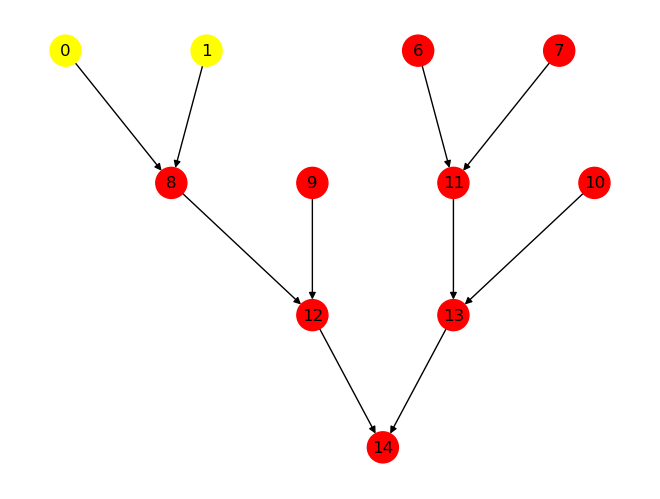

In [10]:
show_graph_with_labels(adj, l, label_names, True)

In [11]:
 # sudo apt-get install graphviz